# prompt 

dame un cuaderno Jupyter o archivo .ipynb con un diseño de una clase, bien completa, sobre: "Análisis descriptivo de datos utilizando Pandas y Matplotlib", de 3 horas para la formación de estudiantes del segundo semestre de la carrera de Matemáticas en Caucasia - Antioquia (Colombia). Donde los temas a desarrollar sean:  

1. Análisis de datos utilizando visualización tabular
2. Análisis de datos utilizando visualización gráfica. 


Todo con una orientación hacia su utilización en ciencia de datos con ejemplos de la Teoría Elemental de Números y pensando en desarrollar las habilidades computacionales de los estudiantes para el curso de Métodos Numéricos I que verán en dos semestres. Esta es una clase para estudiantes que ya tienen los conceptos adquiricos de Tipos de datos, Estructuras de datos incorporadas en Python, Operadores, condicionales, ciclos, funciones de usuario de Python, NumPy (y su estructura nd-array), Pandas (y su estructura DataFrame), Matplotlib (Visualización de datos), Archivos de Datos .csv y Bases de Datos .db de SQL. Y esto teniendo en cuenta que el siguiente tema en este curso es "Exposición de codificación y descripción de código Python de las temáticas del curso".

# Clase: Análisis descriptivo de datos con Pandas y Matplotlib
**Programa:** Matemáticas — segundo semestre  
**Contexto:** Universidad de Antioquia, Campus Caucasia (Antioquia, Colombia)  
**Duración:** 3 horas (180 minutos)  
**Área de aplicación:** Teoría Elemental de Números y ciencia de datos

---



## 1. Propósito de la sesión

Transformar datos matemáticos en evidencia descriptiva mediante tablas, resúmenes estadísticos y visualizaciones gráficas. Se estudiarán propiedades aritméticas de los números naturales y se construirán interpretaciones que distingan entre **calcular una cantidad**, **describir un conjunto de datos** y **argumentar matemáticamente a partir de los resultados**.

La sesión conecta la programación de segundo semestre con el futuro curso de **Métodos Numéricos I**: generación reproducible de datos, análisis de errores de interpretación, comparación de magnitudes, observación de patrones y comunicación de resultados computacionales.



### Objetivo general
Analizar descriptivamente un conjunto de datos construido a partir de propiedades de los números naturales, utilizando `pandas.DataFrame` para la visualización tabular y `matplotlib` para la visualización gráfica, formulando e interpretando preguntas matemáticas.



### Resultados de aprendizaje
Al finalizar, el estudiante podrá:

1. Reconocer la estructura, dimensiones, tipos y calidad básica de un conjunto de datos.
2. Seleccionar filas y columnas, ordenar, filtrar y agrupar datos con Pandas.
3. Calcular e interpretar medidas descriptivas pertinentes, sin confundirlas con demostraciones.
4. Construir gráficos adecuados a la pregunta y describir patrones, variabilidad y posibles valores atípicos.
5. Formular conclusiones reproducibles y comunicar las limitaciones del análisis.
6. Explicar el flujo de un programa Python: entradas, transformaciones, salidas y propósito de las funciones.



### Saberes previos requeridos
Tipos y estructuras incorporadas de Python; operadores, condicionales, ciclos y funciones; NumPy y arreglos `ndarray`; Pandas y `DataFrame`; Matplotlib; lectura de archivos CSV y nociones de bases de datos SQLite (`.db`).



## Pregunta orientadora
**¿Qué patrones aparecen al estudiar computacionalmente las propiedades aritméticas de los primeros 500 números naturales, y cuáles de esos patrones podemos describir con tablas y gráficos?**

> Convención: en este cuaderno se trabaja con los enteros positivos $1,2,\ldots, 500$. El número 1 no se considera primo ni compuesto.

## 2. Secuencia didáctica de 180 minutos

| Momento | Tiempo | Actividad y evidencia |
|---|---:|---|
| Apertura y pregunta orientadora | 10 min | Discusión: ¿qué significa describir datos matemáticos? |
| Preparación y construcción del conjunto de datos | 25 min | Ejecutar y explicar las funciones de teoría de números. |
| Análisis tabular con Pandas | 40 min | Inspección, selección, filtros, ordenamientos, agrupaciones y resúmenes. |
| Pausa activa | 5 min | Pregunta breve: ¿una media describe necesariamente un objeto matemático? |
| Análisis gráfico con Matplotlib | 45 min | Histogramas, barras, líneas, dispersión y diagramas de caja. |
| Laboratorio de interpretación | 35 min | Resolver preguntas, contrastar tablas y gráficos y redactar conclusiones. |
| Cierre y puente a la siguiente clase | 20 min | Socialización, evaluación rápida y preparación de exposición de código. |
| **Total** | **180 min** | |

**Estrategia metodológica:** aula-taller con demostración breve, programación guiada, resolución de problemas y discusión por parejas. Se recomienda que cada estudiante ejecute las celdas, modifique parámetros y explique al menos una decisión de análisis.

## 3. Planteamiento matemático y diseño de datos

Para cada entero positivo \(n\), construiremos variables derivadas de su factorización y sus divisores:

- `n`: entero estudiado.
- `es_primo`: indicador booleano de primalidad.
- `num_divisores` ($\tau(n)$): cantidad de divisores positivos.
- `suma_divisores` ($\sigma(n)$): suma de los divisores positivos.
- `phi` ($\varphi(n)$): cantidad de enteros de $1$ a $n$ coprimos con $n$.
- `factores_primos_distintos`: cantidad de factores primos distintos.
- `mayor_factor_primo`: mayor factor primo; para $n=1$, se registra 1 como convención computacional.
- `residuo_mod_6`: residuo al dividir entre 6.



**Nota epistemológica:** los datos se generan mediante algoritmos exactos para este rango. Los gráficos permiten explorar regularidades y formular conjeturas, pero una visualización o una correlación no constituye por sí sola una demostración matemática.

### 3.1 Importación de bibliotecas

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración reproducible de presentación
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.3.5


### 3.2 Funciones de Teoría Elemental de Números

In [2]:
def es_primo(n):
    """Determina si n es primo mediante divisiones hasta sqrt(n)."""
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False
    divisor = 3
    while divisor * divisor <= n:
        if n % divisor == 0:
            return False
        divisor += 2
    return True


def divisores_positivos(n):
    """Devuelve la lista ordenada de divisores positivos de n."""
    if n < 1:
        raise ValueError("n debe ser un entero positivo")
    menores, mayores = [], []
    for d in range(1, math.isqrt(n) + 1):
        if n % d == 0:
            menores.append(d)
            if d != n // d:
                mayores.append(n // d)
    return menores + mayores[::-1]


def indicadores_aritmeticos(n):
    """Calcula indicadores aritméticos para un entero positivo n."""
    divs = divisores_positivos(n)
    primos_distintos = set()
    m = n
    p = 2
    while p * p <= m:
        if m % p == 0:
            primos_distintos.add(p)
            while m % p == 0:
                m //= p
        p += 1
    if m > 1:
        primos_distintos.add(m)

    phi = sum(math.gcd(k, n) == 1 for k in range(1, n + 1))
    mayor_factor = max(primos_distintos) if primos_distintos else 1

    return {
        "n": n,
        "es_primo": es_primo(n),
        "num_divisores": len(divs),
        "suma_divisores": sum(divs),
        "phi": phi,
        "factores_primos_distintos": len(primos_distintos),
        "mayor_factor_primo": mayor_factor,
        "residuo_mod_6": n % 6,
        "es_cuadrado_perfecto": math.isqrt(n) ** 2 == n
    }


# Pruebas unitarias sencillas: verificar casos conocidos
assert es_primo(2) and es_primo(97) and not es_primo(1) and not es_primo(91)
assert divisores_positivos(12) == [1, 2, 3, 4, 6, 12]
assert indicadores_aritmeticos(12)["phi"] == 4

print("Las pruebas básicas fueron superadas.")

Las pruebas básicas fueron superadas.


### 3.3 Generación del conjunto de datos

In [3]:
N_MAX = 500  # Modifique a 100, 500 o 1000 y observe el efecto.
registros = [indicadores_aritmeticos(n) for n in range(1, N_MAX + 1)]
df = pd.DataFrame(registros)

df.head(10)

,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto
0,1,False,1,1,1,0,1,1,True
1,2,True,2,3,1,1,2,2,False
2,3,True,2,4,2,1,3,3,False
3,4,False,3,7,2,1,2,4,True
4,5,True,2,6,4,1,5,5,False
5,6,False,4,12,2,2,3,0,False
6,7,True,2,8,6,1,7,1,False
7,8,False,4,15,4,1,2,2,False
8,9,False,3,13,6,1,3,3,True
9,10,False,4,18,4,2,5,4,False


**Discusión guiada.** Antes de continuar, respondan:

1. ¿Qué representa cada fila? ¿Qué representa cada columna?
2. ¿Por qué `es_primo` es una variable booleana?
3. ¿Qué diferencia hay entre una variable original (`n`) y una variable derivada (`num_divisores`)?
4. ¿Qué supuesto computacional se adoptó para `mayor_factor_primo` cuando \(n=1\)?

## 4. Análisis de datos mediante visualización tabular (40 min)

Las tablas permiten inspeccionar valores concretos, verificar transformaciones y resumir grupos. Una tabla es especialmente útil cuando necesitamos conocer el valor exacto de una observación; no siempre permite percibir tendencias globales con facilidad.

### 4.1 Inspección estructural

In [4]:
print("Primeras filas:")
display(df.head())

print("Últimas filas:")
display(df.tail())

print("Dimensiones (filas, columnas):", df.shape)
print("\nNombres de columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nInformación general:")
df.info()

Primeras filas:


,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto
0,1,False,1,1,1,0,1,1,True
1,2,True,2,3,1,1,2,2,False
2,3,True,2,4,2,1,3,3,False
3,4,False,3,7,2,1,2,4,True
4,5,True,2,6,4,1,5,5,False


Últimas filas:


,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto
495,496,False,10,992,240,2,31,4,False
496,497,False,4,576,420,2,71,5,False
497,498,False,8,1008,164,3,83,0,False
498,499,True,2,500,498,1,499,1,False
499,500,False,12,1092,200,2,5,2,False


Dimensiones (filas, columnas): (500, 9)

Nombres de columnas:
['n', 'es_primo', 'num_divisores', 'suma_divisores', 'phi', 'factores_primos_distintos', 'mayor_factor_primo', 'residuo_mod_6', 'es_cuadrado_perfecto']

Tipos de datos:
n                            int64
es_primo                      bool
num_divisores                int64
suma_divisores               int64
phi                          int64
factores_primos_distintos    int64
mayor_factor_primo           int64
residuo_mod_6                int64
es_cuadrado_perfecto          bool
dtype: object

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   n                          500 non-null    int64
 1   es_primo                   500 non-null    bool 
 2   num_divisores              500 non-null    int64
 3   suma_divisores             500 non-null

### 4.2 Calidad y consistencia de los datos

In [5]:
resumen_calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "valores_unicos": df.nunique(),
    "porcentaje_faltantes": 100 * df.isna().mean()
})
display(resumen_calidad)

print("¿Hay filas duplicadas?", df.duplicated().any())
print("¿Hay valores faltantes?", df.isna().any().any())
print("¿Todos los n son únicos?", df["n"].is_unique)

,tipo,faltantes,valores_unicos,porcentaje_faltantes
n,int64,0,500,0.000
es_primo,bool,0,2,0.000
num_divisores,int64,0,17,0.000
suma_divisores,int64,0,255,0.000
phi,int64,0,141,0.000
factores_primos_distintos,int64,0,5,0.000
mayor_factor_primo,int64,0,96,0.000
residuo_mod_6,int64,0,6,0.000
es_cuadrado_perfecto,bool,0,2,0.000


¿Hay filas duplicadas? False
¿Hay valores faltantes? False
¿Todos los n son únicos? True


**Interpretación:** en este conjunto generado por código esperamos no encontrar faltantes ni filas duplicadas. En datos reales, estas comprobaciones son indispensables antes de calcular estadísticas. Un dato faltante no debe reemplazarse automáticamente por cero: primero hay que comprender qué significa su ausencia.

### 4.3 Selección de columnas, filas y observaciones

In [6]:
# Una columna: devuelve una Serie
display(df["num_divisores"].head())

# Varias columnas: devuelve un DataFrame
display(df[["n", "es_primo", "num_divisores", "phi"]].head(12))

# Selección por posición
display(df.iloc[10:20, 0:5])

# Selección por condición
primos = df.loc[df["es_primo"], ["n", "num_divisores", "phi"]]
display(primos.head(15))

0    1
1    2
2    2
3    3
4    2
Name: num_divisores, dtype: int64

,n,es_primo,num_divisores,phi
0,1,False,1,1
1,2,True,2,1
2,3,True,2,2
3,4,False,3,2
4,5,True,2,4
5,6,False,4,2
6,7,True,2,6
7,8,False,4,4
8,9,False,3,6
9,10,False,4,4


,n,es_primo,num_divisores,suma_divisores,phi
10,11,True,2,12,10
11,12,False,6,28,4
12,13,True,2,14,12
13,14,False,4,24,6
14,15,False,4,24,8
15,16,False,5,31,8
16,17,True,2,18,16
17,18,False,6,39,6
18,19,True,2,20,18
19,20,False,6,42,8


,n,num_divisores,phi
1,2,2,1
2,3,2,2
4,5,2,4
6,7,2,6
10,11,2,10
12,13,2,12
16,17,2,16
18,19,2,18
22,23,2,22
28,29,2,28


### 4.4 Filtrar y ordenar

In [7]:
# Números con más de 10 divisores
muchos_divisores = df.loc[df["num_divisores"] > 10]
display(muchos_divisores.head(15))

# Números con exactamente 8 divisores
exactamente_ocho = df.query("num_divisores == 8")
display(exactamente_ocho.head(15))

# Ordenar por cantidad de divisores, de mayor a menor
display(df.sort_values("num_divisores", ascending=False).head(12))

# Números no primos con phi(n) relativamente pequeño
display(df.loc[(~df["es_primo"]) & (df["phi"] < 50)].head(15))

,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto
59,60,False,12,168,16,3,5,0,False
71,72,False,12,195,24,2,3,0,False
83,84,False,12,224,24,3,7,0,False
89,90,False,12,234,24,3,5,0,False
95,96,False,12,252,32,2,3,0,False
107,108,False,12,280,36,2,3,0,False
119,120,False,16,360,32,3,5,0,False
125,126,False,12,312,36,3,7,0,False
131,132,False,12,336,40,3,11,0,False
139,140,False,12,336,48,3,7,2,False


,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto
23,24,False,8,60,8,2,3,0,False
29,30,False,8,72,8,3,5,0,False
39,40,False,8,90,16,2,5,4,False
41,42,False,8,96,12,3,7,0,False
53,54,False,8,120,18,2,3,0,False
55,56,False,8,120,24,2,7,2,False
65,66,False,8,144,20,3,11,0,False
69,70,False,8,144,24,3,7,4,False
77,78,False,8,168,24,3,13,0,False
87,88,False,8,180,40,2,11,4,False


,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto
419,420,False,24,1344,96,4,7,0,False
479,480,False,24,1512,128,3,5,0,False
359,360,False,24,1170,96,3,5,0,False
431,432,False,20,1240,144,2,3,0,False
239,240,False,20,744,64,3,5,0,False
335,336,False,20,992,96,3,7,0,False
449,450,False,18,1209,120,3,5,0,False
395,396,False,18,1092,120,3,11,0,False
287,288,False,18,819,96,2,3,0,False
467,468,False,18,1274,144,3,13,0,False


,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto
0,1,False,1,1,1,0,1,1,True
3,4,False,3,7,2,1,2,4,True
5,6,False,4,12,2,2,3,0,False
7,8,False,4,15,4,1,2,2,False
8,9,False,3,13,6,1,3,3,True
9,10,False,4,18,4,2,5,4,False
11,12,False,6,28,4,2,3,0,False
13,14,False,4,24,6,2,7,2,False
14,15,False,4,24,8,2,5,3,False
15,16,False,5,31,8,1,2,4,True


### 4.5 Resúmenes estadísticos

In [8]:
# Resumen de variables numéricas
display(df.describe())

# Medidas seleccionadas para la función tau(n)
tau = df["num_divisores"]
medidas_tau = pd.Series({
    "media": tau.mean(),
    "mediana": tau.median(),
    "moda": tau.mode().tolist(),
    "mínimo": tau.min(),
    "máximo": tau.max(),
    "desviación estándar": tau.std(),
    "primer cuartil": tau.quantile(0.25),
    "tercer cuartil": tau.quantile(0.75)
})
display(medidas_tau)

,n,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6
count,500.000,500.000,500.000,500.000,500.000,500.000,500.000
mean,250.500,6.380,411.766,152.232,2.016,75.548,2.496
std,144.482,4.231,284.110,112.478,0.710,107.443,1.708
min,1.000,1.000,1.000,1.000,0.000,1.000,0.000
25%,125.750,4.000,185.250,64.000,2.000,11.000,1.000
50%,250.500,4.000,372.000,128.000,2.000,29.000,2.000
75%,375.250,8.000,576.000,216.000,2.000,89.000,4.000
max,500.000,24.000,"1,512.000",498.000,4.000,499.000,5.000


media                 6.380
mediana               4.000
moda                    [4]
mínimo                    1
máximo                   24
desviación estándar   4.231
primer cuartil        4.000
tercer cuartil        8.000
dtype: object

**Preguntas de interpretación**

- ¿Qué significa que la media y la mediana de \(	au(n)\) sean diferentes?
- ¿La media de la cantidad de divisores tiene que ser un entero? ¿Por qué?
- ¿Qué información aporta el rango intercuartílico \(Q_3-Q_1\)?
- ¿La desviación estándar describe la dispersión de los valores de \(n\), o la de `num_divisores` en este cálculo?

### 4.6 Frecuencias y tablas de contingencia

In [9]:
# Frecuencia absoluta de cada cantidad de divisores
frecuencia_tau = df["num_divisores"].value_counts().sort_index()
display(frecuencia_tau.rename("frecuencia absoluta").to_frame())

# Frecuencia relativa
frecuencia_relativa = df["num_divisores"].value_counts(normalize=True).sort_index()
display((100 * frecuencia_relativa).rename("porcentaje (%)").to_frame())

# Tabla cruzada: primalidad y residuo módulo 6
tabla_primos_residuo = pd.crosstab(
    df["residuo_mod_6"], df["es_primo"],
    rownames=["Residuo módulo 6"],
    colnames=["¿Es primo?"]
)
display(tabla_primos_residuo)

# Proporción de primos dentro de cada residuo
proporcion_primos = df.groupby("residuo_mod_6")["es_primo"].mean()
display(proporcion_primos.rename("proporción de primos").to_frame())

,frecuencia absoluta
num_divisores,
1,1
2,95
3,8
4,149
5,2
6,59
7,1
8,87
9,7


,porcentaje (%)
num_divisores,
1,0.200
2,19.000
3,1.600
4,29.800
5,0.400
6,11.800
7,0.200
8,17.400
9,1.400


¿Es primo?,False,True
Residuo módulo 6,,
0,83,0
1,39,45
2,83,1
3,82,1
4,83,0
5,35,48


,proporción de primos
residuo_mod_6,
0,0.000
1,0.536
2,0.012
3,0.012
4,0.000
5,0.578


### 4.7 Agrupación por intervalos

In [10]:
# Dividir los naturales estudiados en intervalos de 50 unidades
df["intervalo_50"] = pd.cut(
    df["n"],
    bins=list(range(0, N_MAX + 51, 50)),
    right=True,
    include_lowest=True
)

resumen_intervalos = df.groupby("intervalo_50", observed=False).agg(
    cantidad_n=("n", "count"),
    cantidad_primos=("es_primo", "sum"),
    promedio_divisores=("num_divisores", "mean"),
    promedio_phi=("phi", "mean")
)
resumen_intervalos["porcentaje_primos"] = (
    100 * resumen_intervalos["cantidad_primos"] / resumen_intervalos["cantidad_n"]
)
display(resumen_intervalos)

,cantidad_n,cantidad_primos,promedio_divisores,promedio_phi,porcentaje_primos
intervalo_50,,,,,
"(-0.001, 50.0]",50,15,4.140,15.480,30.000
"(50.0, 100.0]",50,10,5.500,45.400,20.000
"(100.0, 150.0]",50,10,5.960,76.280,20.000
"(150.0, 200.0]",50,11,6.360,107.480,22.000
"(200.0, 250.0]",50,7,6.460,135.840,14.000
"(250.0, 300.0]",50,9,6.920,167.480,18.000
"(300.0, 350.0]",50,8,6.820,198.640,16.000
"(350.0, 400.0]",50,8,7.200,226.960,16.000
"(400.0, 450.0]",50,9,7.220,259.120,18.000


### Actividad tabular 1 — Exploración dirigida (en parejas)

Completen las instrucciones y escriban una interpretación de dos o tres frases por pregunta.

1. Muestren los primeros 20 números primos del conjunto.
2. Encuentren los cinco números con mayor cantidad de divisores.
3. ¿Cuántos cuadrados perfectos hay entre 1 y 500?
4. Construyan una tabla con el promedio de \(
arphi(n)\) para cada residuo módulo 6.
5. Identifiquen si todos los primos mayores que 3 tienen residuo 1 o 5 módulo 6. Verifiquen con una tabla y expliquen por qué la observación no afirma que todo número de esos residuos sea primo.

**Espacio de trabajo:** escriban código en las celdas siguientes.

In [11]:
# 1. Primeros 20 primos
# Completar:
# ...

# 2. Cinco números con más divisores
# ...

# 3. Cantidad de cuadrados perfectos
# ...

# 4. Promedio de phi por residuo módulo 6
# ...

# 5. Verificación de la condición para primos mayores que 3
# ...

## 5. Análisis de datos mediante visualización gráfica (45 min)

Un gráfico debe responder una pregunta. Antes de elegirlo, identifiquen: (i) qué variables se comparan, (ii) si son cualitativas o cuantitativas, (iii) qué patrón se busca y (iv) qué conclusión permite —y cuál no permite— el gráfico.

Usaremos Matplotlib directamente, con títulos, etiquetas, unidades o convenciones explícitas y cuadrícula cuando facilite la lectura.

### 5.1 Distribución de la cantidad de divisores: histograma

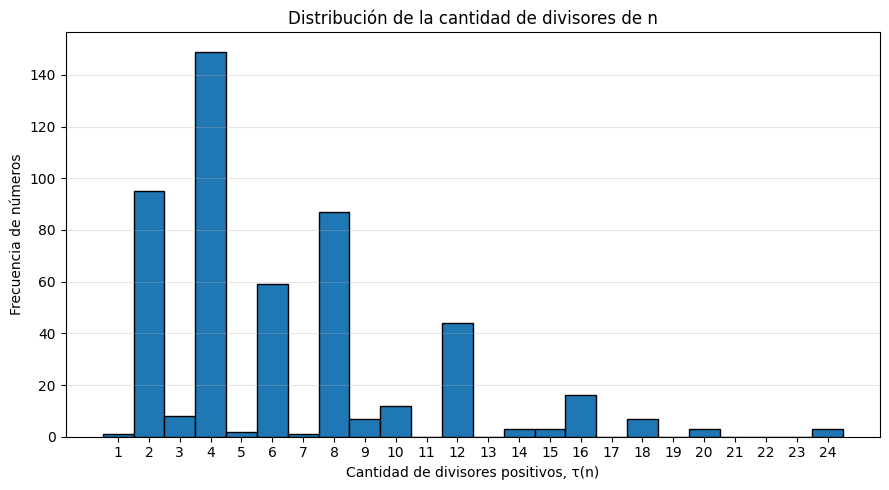

In [12]:
plt.figure(figsize=(9, 5))
plt.hist(df["num_divisores"], bins=range(1, df["num_divisores"].max() + 2),
         edgecolor="black", align="left")
plt.title("Distribución de la cantidad de divisores de n")
plt.xlabel("Cantidad de divisores positivos, τ(n)")
plt.ylabel("Frecuencia de números")
plt.xticks(range(1, df["num_divisores"].max() + 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura del histograma:** cada barra representa cuántos valores de \(n\) tienen una cantidad determinada de divisores. No representa la distribución de los propios divisores. ¿Qué valores de \(	au(n)\) son más frecuentes en el rango estudiado?

### 5.2 Frecuencia de primos por intervalos: gráfico de barras

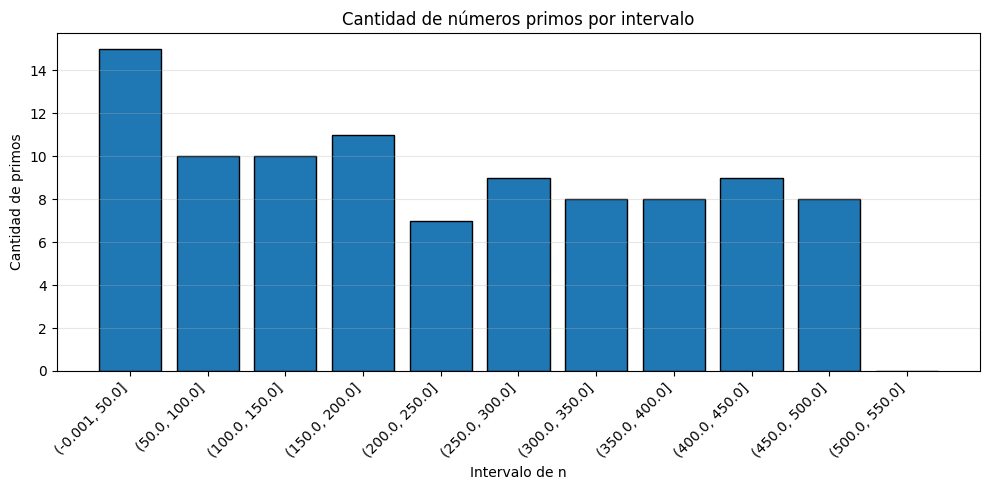

In [13]:
plt.figure(figsize=(10, 5))
x = resumen_intervalos.index.astype(str)
plt.bar(x, resumen_intervalos["cantidad_primos"], edgecolor="black")
plt.title("Cantidad de números primos por intervalo")
plt.xlabel("Intervalo de n")
plt.ylabel("Cantidad de primos")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 5.3 Proporción de primos por intervalos: comparación justa

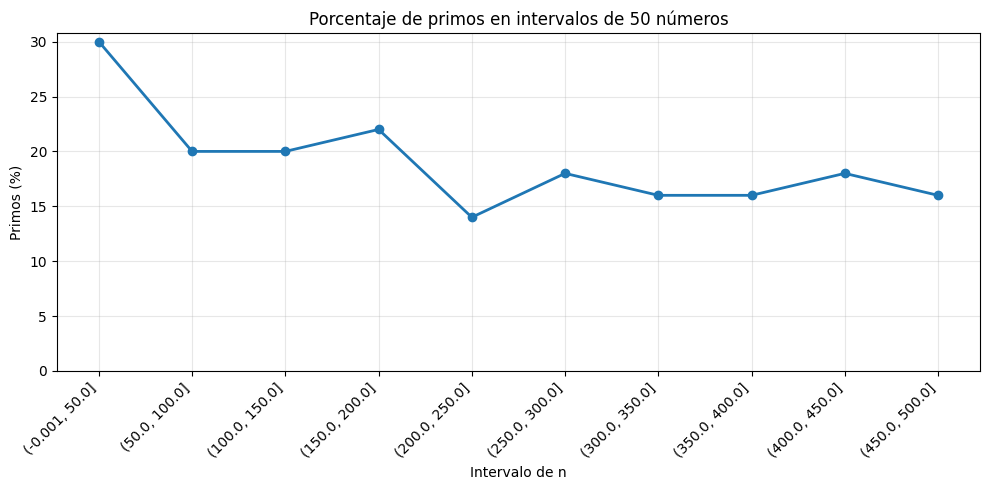

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(x, resumen_intervalos["porcentaje_primos"],
         marker="o", linewidth=2)
plt.title("Porcentaje de primos en intervalos de 50 números")
plt.xlabel("Intervalo de n")
plt.ylabel("Primos (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Discusión:** la cantidad absoluta de primos por intervalo y el porcentaje de primos responden preguntas distintas. En intervalos de igual tamaño suelen coincidir en su denominador, pero el porcentaje ayuda a comunicar una proporción. ¿Qué tendencia observan? ¿Es suficiente este rango para afirmar una ley asintótica? No.

### 5.4 Relación entre n y la cantidad de divisores: dispersión

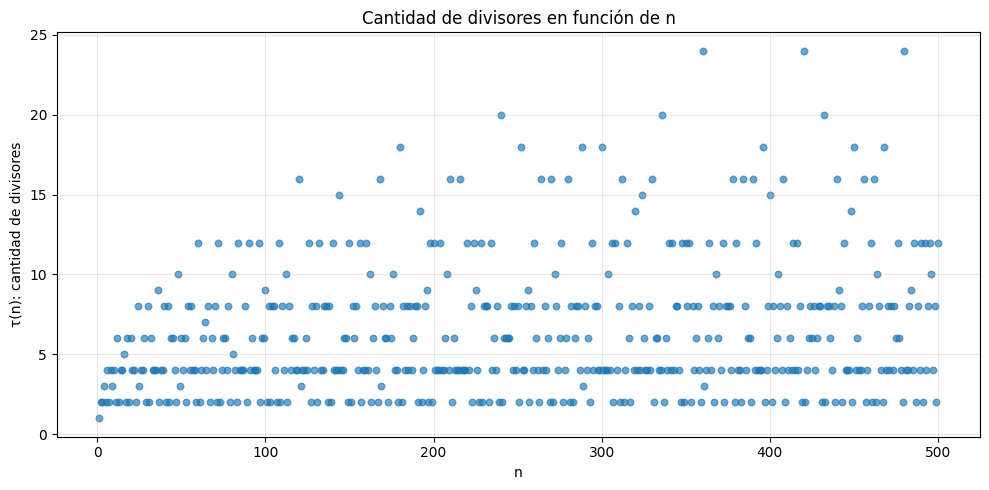

In [15]:
plt.figure(figsize=(10, 5))
plt.scatter(df["n"], df["num_divisores"], alpha=0.65, s=22)
plt.title("Cantidad de divisores en función de n")
plt.xlabel("n")
plt.ylabel("τ(n): cantidad de divisores")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura:** busquen puntos altos y agrupamientos. ¿Un número mayor tiene necesariamente más divisores que uno menor? Usen puntos concretos del gráfico y una tabla para justificar su respuesta.

### 5.5 Comparación de φ(n) con n

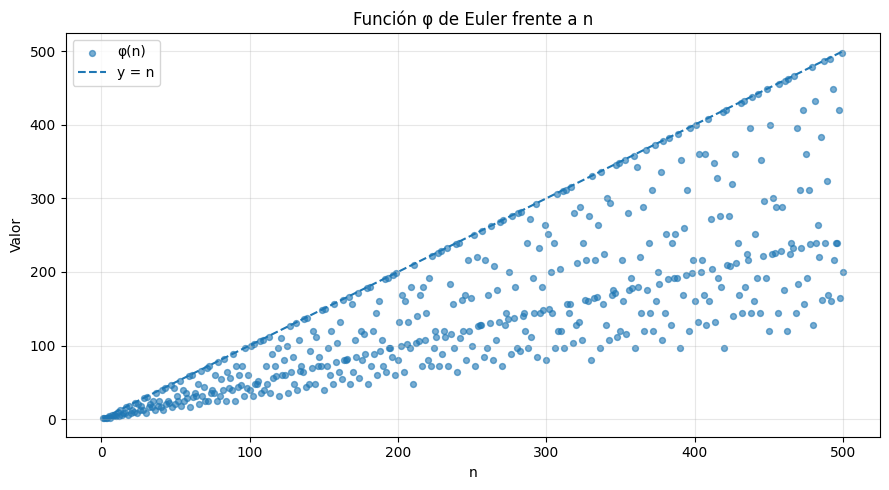

In [16]:
plt.figure(figsize=(9, 5))
plt.scatter(df["n"], df["phi"], s=18, alpha=0.6, label="φ(n)")
plt.plot(df["n"], df["n"], linestyle="--", label="y = n")
plt.title("Función φ de Euler frente a n")
plt.xlabel("n")
plt.ylabel("Valor")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Pregunta:** ¿por qué \(
arphi(n)\leq n\)? ¿Para qué valores se alcanza la igualdad? Conecten la respuesta con la definición de coprimalidad y no solamente con la forma de la nube de puntos.

### 5.6 Diagrama de caja: cantidad de divisores según primalidad

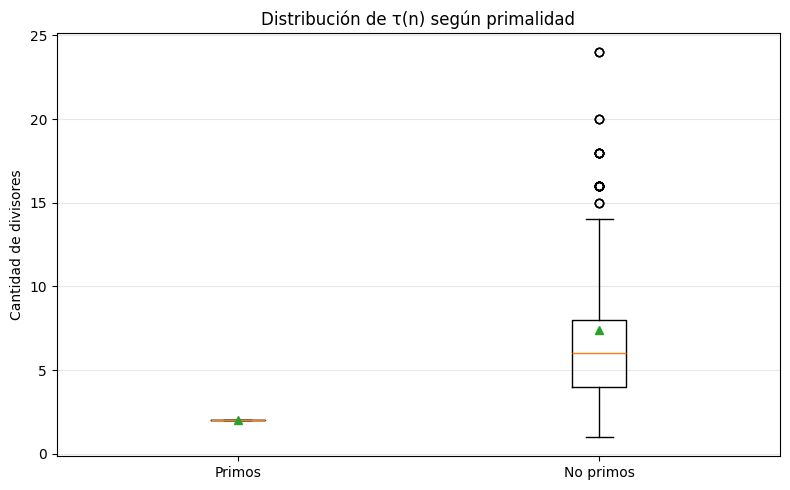

In [17]:
datos_caja = [
    df.loc[df["es_primo"], "num_divisores"],
    df.loc[~df["es_primo"], "num_divisores"]
]
plt.figure(figsize=(8, 5))
plt.boxplot(datos_caja, tick_labels=["Primos", "No primos"], showmeans=True)
plt.title("Distribución de τ(n) según primalidad")
plt.ylabel("Cantidad de divisores")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Advertencia de interpretación:** los primos tienen exactamente dos divisores positivos por definición (para \(n>1\)). En el grupo “no primos” se mezclan el número 1 y los compuestos. La caja resume una distribución; no reemplaza la definición matemática.

### 5.7 Gráfico de residuos módulo 6

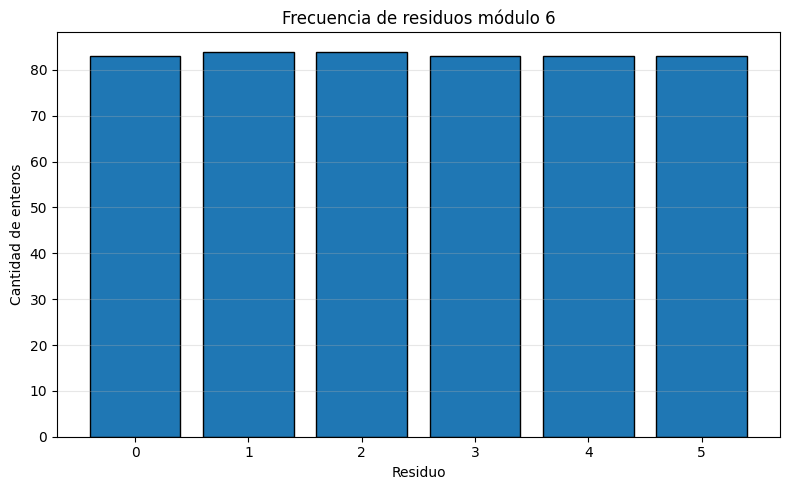

In [18]:
conteo_residuos = df["residuo_mod_6"].value_counts().sort_index()
plt.figure(figsize=(8, 5))
plt.bar(conteo_residuos.index.astype(str), conteo_residuos.values, edgecolor="black")
plt.title("Frecuencia de residuos módulo 6")
plt.xlabel("Residuo")
plt.ylabel("Cantidad de enteros")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Actividad gráfica 2 — Diseñar una visualización

Elijan una pregunta que todavía no haya sido respondida por los gráficos anteriores. Algunas posibilidades:

- ¿Cómo cambia la media de \(	au(n)\) por intervalos de 50?
- ¿Qué relación visual aparece entre el número de factores primos distintos y \(
arphi(n)\)?
- ¿Cómo se distribuyen los cuadrados perfectos?
- ¿Qué diferencias hay entre la suma de divisores y el propio número?

Construyan un gráfico apropiado, con título, ejes, leyenda si es necesaria y una interpretación escrita. Eviten adornos que dificulten la lectura.

In [19]:
# Escriba aquí su visualización original.
# 1. Formule la pregunta en un comentario.
# 2. Seleccione las variables.
# 3. Construya el gráfico.
# 4. Interprete lo observado.

## 6. Laboratorio integrador: de la pregunta a la conclusión (35 min)

### Reto de investigación breve

**Pregunta:** ¿Cómo se comporta la cantidad de divisores positivos \(	au(n)\) en los números naturales estudiados y qué diferencias descriptivas se observan entre primos, cuadrados perfectos y otros compuestos?

**Producto del equipo:** una mini-nota de análisis de datos con:
1. Pregunta investigable y población/rango estudiado.
2. Tabla con al menos tres estadísticas relevantes.
3. Dos gráficos complementarios.
4. Tres conclusiones respaldadas por valores o patrones observables.
5. Una limitación del análisis y una pregunta nueva.

### Código de apoyo: clasificación de grupos


In [20]:
def clasificar_numero(fila):
    if fila["n"] == 1:
        return "unidad"
    if fila["es_primo"]:
        return "primo"
    if fila["es_cuadrado_perfecto"]:
        return "cuadrado compuesto"
    return "otro compuesto"

df["tipo_numero"] = df.apply(clasificar_numero, axis=1)

resumen_tipos = df.groupby("tipo_numero").agg(
    cantidad=("n", "count"),
    media_tau=("num_divisores", "mean"),
    mediana_tau=("num_divisores", "median"),
    maximo_tau=("num_divisores", "max"),
    media_phi=("phi", "mean")
)
display(resumen_tipos)

,cantidad,media_tau,mediana_tau,maximo_tau,media_phi
tipo_numero,,,,,
cuadrado compuesto,21,7.095,7.000,15,105.524
otro compuesto,383,7.441,6.000,24,136.966
primo,95,2.000,2.000,2,225.695
unidad,1,1.000,1.000,1,1.000


### Reto: tabla y gráfico comparativo

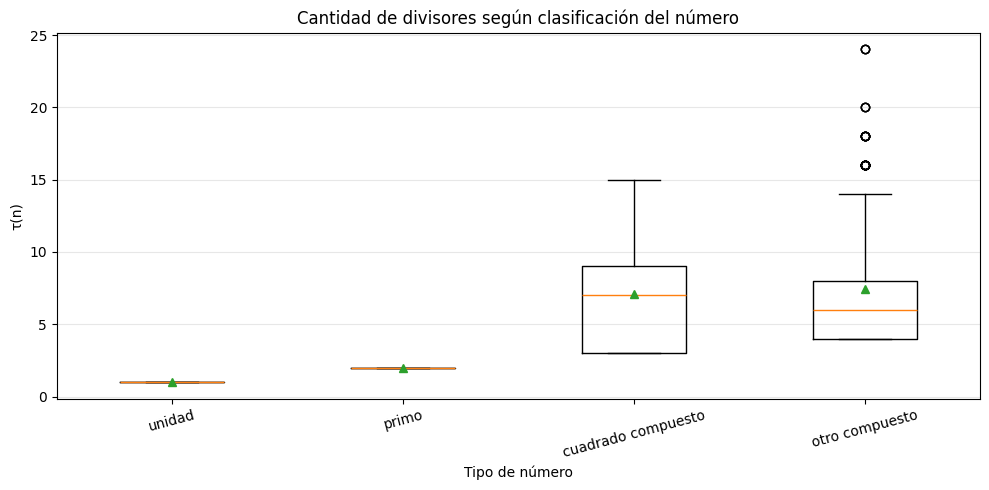

In [21]:
# Gráfico de cajas por tipo de número
orden = ["unidad", "primo", "cuadrado compuesto", "otro compuesto"]
grupos = [df.loc[df["tipo_numero"] == t, "num_divisores"] for t in orden]

plt.figure(figsize=(10, 5))
plt.boxplot(grupos, tick_labels=orden, showmeans=True)
plt.title("Cantidad de divisores según clasificación del número")
plt.xlabel("Tipo de número")
plt.ylabel("τ(n)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Preguntas para orientar la discusión

- ¿Por qué el grupo de primos presenta una variabilidad nula en \(	au(n)\)?
- ¿Qué diferencia hay entre un cuadrado perfecto primo y un cuadrado perfecto compuesto? ¿Existe el primero?
- ¿Qué información se pierde al resumir un grupo únicamente con su media?
- ¿Qué cambia si se amplía el análisis de 500 a 5 000 números?
- ¿Qué parte del resultado depende de una definición matemática y qué parte depende del rango y del algoritmo elegido?

**Criterio de rigor:** indiquen siempre el rango analizado. No generalicen a todos los naturales una observación obtenida solamente hasta 500.

## 7. Exportación y reproducibilidad

Un análisis de datos debe poder repetirse. Guardaremos el conjunto en CSV y lo leeremos de nuevo para verificar que la estructura se conserva. En un entorno local, el archivo se guardará en el directorio de trabajo del cuaderno.

In [22]:
# Exportar datos
ruta_csv = "datos_teoria_numeros.csv"
df.to_csv(ruta_csv, index=False, encoding="utf-8")
print(f"Archivo guardado: {ruta_csv}")

# Leer nuevamente
df_verificacion = pd.read_csv(ruta_csv)
display(df_verificacion.head())

print("Dimensiones originales:", df.shape)
print("Dimensiones recuperadas:", df_verificacion.shape)
print("¿Coinciden las columnas?", df.columns.tolist() == df_verificacion.columns.tolist())

Archivo guardado: datos_teoria_numeros.csv


,n,es_primo,num_divisores,suma_divisores,phi,factores_primos_distintos,mayor_factor_primo,residuo_mod_6,es_cuadrado_perfecto,intervalo_50,tipo_numero
0,1,False,1,1,1,0,1,1,True,"(-0.001, 50.0]",unidad
1,2,True,2,3,1,1,2,2,False,"(-0.001, 50.0]",primo
2,3,True,2,4,2,1,3,3,False,"(-0.001, 50.0]",primo
3,4,False,3,7,2,1,2,4,True,"(-0.001, 50.0]",cuadrado compuesto
4,5,True,2,6,4,1,5,5,False,"(-0.001, 50.0]",primo


Dimensiones originales: (500, 11)
Dimensiones recuperadas: (500, 11)
¿Coinciden las columnas? True


**Extensión opcional con SQLite:** dado que ya conocen bases `.db`, pueden almacenar el DataFrame en una tabla y consultarlo con SQL. El objetivo aquí no es desarrollar SQL, sino reconocer que el mismo conjunto puede persistirse y analizarse desde distintas herramientas.

In [23]:
import sqlite3

ruta_db = "teoria_numeros.db"
df_sql = df.copy()
df_sql["intervalo_50"] = df_sql["intervalo_50"].astype(str)

with sqlite3.connect(ruta_db) as conexion:
    df_sql.to_sql("indicadores_numericos", conexion, if_exists="replace", index=False)
    consulta = pd.read_sql_query(
        """
        SELECT tipo_numero, COUNT(*) AS cantidad,
               AVG(num_divisores) AS promedio_divisores
        FROM indicadores_numericos
        GROUP BY tipo_numero
        ORDER BY cantidad DESC;
        """,
        conexion
    )
display(consulta)

,tipo_numero,cantidad,promedio_divisores
0,otro compuesto,383,7.441
1,primo,95,2.000
2,cuadrado compuesto,21,7.095
3,unidad,1,1.000


## 8. Evaluación formativa

### Lista de cotejo

| Criterio | Logrado | En proceso |
|---|:---:|:---:|
| Inspecciona dimensiones, columnas y tipos de datos. | ☐ | ☐ |
| Selecciona, filtra y ordena filas correctamente. | ☐ | ☐ |
| Calcula e interpreta medidas descriptivas. | ☐ | ☐ |
| Construye una tabla de frecuencias o agrupación. | ☐ | ☐ |
| Selecciona un gráfico coherente con la pregunta. | ☐ | ☐ |
| Rotula el gráfico y comunica su interpretación. | ☐ | ☐ |
| Distingue evidencia descriptiva de demostración matemática. | ☐ | ☐ |
| Explica el propósito de las instrucciones principales. | ☐ | ☐ |

### Rúbrica sugerida para el reto (100 puntos)

| Dimensión | Puntos | Evidencia esperada |
|---|---:|---|
| Pregunta y diseño | 15 | Pregunta clara, rango y variables definidos. |
| Análisis tabular | 25 | Filtros, agrupaciones y estadísticas pertinentes. |
| Visualización | 25 | Dos gráficos legibles y adecuados. |
| Interpretación matemática | 25 | Conclusiones sustentadas, sin generalizaciones indebidas. |
| Reproducibilidad y comunicación | 10 | Código ejecutable y explicación comprensible. |

### Ticket de salida (individual)

Responda en 3–5 líneas cada pregunta:

1. ¿En qué situación usaría una tabla en lugar de un gráfico?
2. ¿Qué diferencia existe entre frecuencia absoluta y relativa?
3. ¿Por qué una asociación visual entre dos variables no prueba causalidad?
4. ¿Qué decisión de diseño tomó al construir su gráfico y por qué?
5. ¿Qué celda o función del cuaderno podría explicar a un compañero con mayor claridad?

## 9. Puente con la siguiente clase: exposición de codificación y descripción de código Python

La próxima temática será **“Exposición de codificación y descripción de código Python de las temáticas del curso”**. Por eso, en esta sesión no basta con ejecutar instrucciones: es necesario comprenderlas y poder comunicarlas.

### Preparación previa a la próxima sesión
Cada equipo elegirá una sección del cuaderno y preparará una exposición breve (5–7 minutos) que incluya:

1. **Problema:** ¿qué pregunta matemática o computacional se intenta responder?
2. **Entradas:** ¿qué datos recibe el código?
3. **Proceso:** ¿qué función, método o transformación se aplica?
4. **Salidas:** ¿qué tabla, estadístico o gráfico se obtiene?
5. **Lectura línea a línea:** explicar las instrucciones principales y los argumentos relevantes.
6. **Validación:** mostrar una prueba, una comparación o un caso conocido.
7. **Interpretación:** explicar qué se puede concluir y qué no.

**Secciones sugeridas para distribuir entre equipos:** funciones aritméticas; creación del DataFrame; filtros y ordenamientos; medidas descriptivas; agrupaciones y tablas cruzadas; histogramas y barras; dispersión y cajas; exportación CSV/SQLite.

### Plantilla para describir código
| Elemento | Pregunta que debe responder el expositor |
|---|---|
| Propósito | ¿Para qué sirve este bloque? |
| Variables | ¿Qué representa cada variable? |
| Método | ¿Qué hace el método de Pandas/Matplotlib utilizado? |
| Parámetros | ¿Qué cambia al modificar sus argumentos? |
| Resultado | ¿Qué tipo de objeto o visualización produce? |
| Verificación | ¿Cómo sabemos que el resultado es razonable? |

### Recomendación didáctica
Pedir que cada equipo modifique un parámetro (por ejemplo, `N_MAX`, el tamaño del intervalo o las columnas de un gráfico), vuelva a ejecutar el cuaderno y explique qué cambió. Esto convierte la exposición en una demostración de comprensión y no en una lectura de código.

## 10. Trabajo independiente

1. Repetir el análisis con \(N=1\,000\) y comparar al menos dos resultados con los de \(N=500\).
2. Investigar la función \(\sigma(n)\), suma de divisores, y formular una pregunta descriptiva.
3. Construir una visualización propia que compare \(\sigma(n)\) con \(n\), justificando la elección del tipo de gráfico.
4. Escribir una conclusión de máximo 200 palabras que incluya una limitación.
5. Preparar la exposición de un bloque de código según la plantilla de la sección 9.

### Recursos y documentación
- [Documentación de Pandas](https://pandas.pydata.org/docs/)
- [Tutoriales de Matplotlib](https://matplotlib.org/stable/tutorials/)
- [Documentación de NumPy](https://numpy.org/doc/)
- [Python — documentación oficial](https://docs.python.org/3/)

---

## 11. Notas para el docente

- **Antes de la clase:** comprobar que `pandas`, `numpy` y `matplotlib` estén instalados; probar “Restart Kernel and Run All”; verificar permisos de escritura en la carpeta.
- **Durante la clase:** alternar explicación y ejecución; solicitar predicciones antes de mostrar resultados; pedir que los estudiantes expliquen qué pregunta responde cada tabla o gráfico.
- **Atención a errores frecuentes:** confundir `Series` y `DataFrame`; interpretar `value_counts()` sin ordenar; olvidar que `mean()` de una columna booleana calcula una proporción; comparar conteos de grupos de tamaños diferentes; asumir que una gráfica demuestra una conjetura.
- **Accesibilidad:** usar etiquetas descriptivas, tamaño de letra legible y no depender únicamente del color para comunicar categorías.
- **Ajuste de tiempo:** si el grupo requiere más acompañamiento, priorizar las secciones 4.1–4.6, 5.1–5.4 y el reto integrador; dejar SQLite como extensión.

**Idea central de la clase:** los métodos computacionales permiten explorar datos y formular preguntas matemáticas con mayor alcance, pero la calidad del conocimiento depende de la definición de las variables, la pertinencia de las representaciones y el rigor de la interpretación.